# **O Gato subiu no telhado: Transformer Explainer**

https://poloclub.github.io/transformer-explainer/


# **Método Transformer e máscara causal**

## O Método Antigo, redes recorrentes (RNNs / LSTMs)

Treinamento:

- Passo 1: "O" $\rightarrow$  "gato"
- Passo 2: "O gato" $\rightarrow$ "subiu"
- Passo 3: "O gato subiu" $\rightarrow$  "no"
- Passo 4: "O gato subiu no" $\rightarrow$  "telhado"

## O Método do Transformer — 1 Único Passo na GPU

No Transformer, a frase inteira entra na GPU de uma vez só como uma matriz de 5 tokens:
$$\text{Entrada} = [\text{"O"}, \text{"gato"}, \text{"subiu"}, \text{"no"}, \text{"telhado"}]$$

Para evitar que a palavra na posição 1 "cole" e veja que a palavra seguinte é "gato", o Transformer aplica uma **Máscara Causal** (ou Máscara Triangular) no mecanismo de atenção.

```

                 O    algoritmo  opera   em   três
O                [ 1       0        0      0     0  ]  --> Preve: "gato"
gato             [ 1       1        0      0     0  ]  --> Preve: "subiu"
subiu            [ 1       1        1      0     0  ]  --> Preve: "no"
no               [ 1       1        1      1     0  ]  --> Preve: "telhado"


```
(1 "pode ver" e 0 "mascarado/invisível")

# **Positional Embedding**

$$\text{Word Embedding}_i = \text{Token Embedding}_i + \text{Positional Embedding}_i$$

No Transformer Original(1) usa-se funções trigonométricas de diferentes frequências para cada dimensão do vetor. Como o seno e o cosseno sempre retornam valores entre $-1.0$ e $+1.0$, o vetor de posição nunca estoura a escala, não importa se estamos no token $1$ ou no token $3 \times 4.096$.



## Exemplo

#### Dicionário de Token Embeddings (Significado)

- "O" $\rightarrow [0.10, -0.20, 0.50, 0.30, 0.10]$
- "gato" $\rightarrow [0.85, 0.12, -0.90, 0.40, 0.15]$
- "subiu" $\rightarrow [0.30, 0.70, 0.10, -0.50, 0.20]$

...

#### Tabela de Positional Embeddings (Ordem)

- $\text{Pos 0}$ (1ª palavra) $\rightarrow [0.00, 1.00, 0.00, 1.00, 0.10]$
- $\text{Pos 1}$ (2ª palavra) $\rightarrow [0.84, 0.54, 0.09, 0.99. 0.15]$
- $\text{Pos 2}$ (3ª palavra) $\rightarrow [0.91, -0.41, 0.18, 0.98, 0.20]$

...

#### Word Embedding, $\color{blue}{\text{não contextual ainda!}}$

$$\text{Word Embedding}_{\text{gato}} = \text{Token Embedding}_{\text{gato}} + \text{Positional Embedding}_{\text{pos(gato) = 1}}$$
$$\text{Word Embedding}_{\text{gato}} = [0.85, 0.12, -0.90, 0.40, 0.15] + [0.84, 0.54, 0.09, 0.99. 0.15] = [1.69, 0.66, -0.81, 1.39, 0.30]$$

<br>
<small>
(1) nota: no GPT há uma "tabela" treinável de posições.

#### Usando Funções Trigonométricas

> Empregam funções como $\sin(\omega_i x)$ e $\cos(\omega_i x)$ com diferentes frequência para cada posição. Consiferando uma representação de 5 dimensões das palavras:

> - Dim 0: $sin(1 \times \text{posição})$
> - Dim 1: $cos(1 \times \text{posição})$
> - Dim 2: $sin(0.1 \times \text{posição})$
> - Dim 3: $cos(0.1 \times \text{posição})$
> - Dim 4: $sin(0.5 \times \text{posição})$

> Assim,

> | $$x$$ | $$sin(1 \times \text{x})$$ | $$cos(1 \times \text{x})$$ | $$sin(0.1 \times \text{x})$$ |$$cos(0.1 \times \text{x})$$ | $$sin(0.5 \times \text{x})$$ |
> |-|-|-|-|-|-|
> | $\text{Pos 0 ("O")}$ |0.00| 1.00| 0.00| 1.00| 0.10|
> | $\text{Pos 1 ("gato")}$ |0.84| 0.54| 0.09| 0.99| 0.15|
> | $\text{Pos 2 ("subiu")}$ |0.91| -0.41| 0.18| 0.98| 0.20|

...

# **Tríade $Q$, $K$, $V$**

In [1]:
import numpy as np

# 1. Definindo os tokens e dimensões simplificadas (d_model = 4, d_k = 3)
tokens = ["O", "gato", "subiu", "no", "telhado"]
num_tokens = len(tokens)
d_model = 4  # Tamanho do embedding inicial
d_k = 3      # Tamanho das projeções Q, K, V

# Semente fixa para reprodutibilidade dos resultados
np.random.seed(42)

# Embeddings de entrada fictícios (Matriz X de formato 5 x 4)
X = np.random.randn(num_tokens, d_model)

# Matrizes de projeção treináveis (W_Q, W_K, W_V de formato 4 x 3)
W_Q = np.random.randn(d_model, d_k)
W_K = np.random.randn(d_model, d_k)
W_V = np.random.randn(d_model, d_k)

# 2. Gerando as Matrizes Q, K e V
Q = X @ W_Q  # Formato (5, 3)
K = X @ W_K  # Formato (5, 3)
V = X @ W_V  # Formato (5, 3)

# 3. Passo A: Produto Escalar (Q @ K.T) para medir similaridades
scores = Q @ K.T  # Formato (5, 5)

# 4. Passo B: Escalonamento dividindo pela raiz quadrada de d_k
scaled_scores = scores / np.sqrt(d_k)

# 5. Passo C: Função Softmax por linha para gerar os Pesos de Atenção (Attention Weights)
def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=-1, keepdims=True)

attention_weights = softmax(scaled_scores)  # Formato (5, 5)

# 6. Passo D: Multiplicação dos pesos pela matriz de Valores (V)
output = attention_weights @ V  # Formato (5, 3)

# --- IMPRESSÃO DOS RESULTADOS ---
print("--- MATRIZ DE PESOS DE ATENÇÃO (Softmax) ---")
print("Linha = Palavra buscando contexto (Query) | Coluna = Palavra atendida (Key)\n")
header = f"{'':10} " + " ".join([f"{t:>8}" for t in tokens])
print(header)
for i, token in enumerate(tokens):
    weights_str = " ".join([f"{w:8.3f}" for w in attention_weights[i]])
    print(f"{token:10} {weights_str}")

print("\n--- MATRIZ DE SAÍDA CONTEXTUALIZADA (Output = Attention @ V) ---")
print("Formato final:", output.shape)
print(output)

--- MATRIZ DE PESOS DE ATENÇÃO (Softmax) ---
Linha = Palavra buscando contexto (Query) | Coluna = Palavra atendida (Key)

                  O     gato    subiu       no  telhado
O             0.073    0.117    0.002    0.808    0.001
gato          0.131    0.777    0.062    0.001    0.029
subiu         0.183    0.262    0.319    0.010    0.227
no            0.000    0.000    0.000    1.000    0.000
telhado       0.020    0.021    0.471    0.000    0.488

--- MATRIZ DE SAÍDA CONTEXTUALIZADA (Output = Attention @ V) ---
Formato final: (5, 3)
[[-2.50377197e+00 -5.04967045e-01  3.24360549e+00]
 [ 9.42526565e-01  3.36494421e-01  1.85808013e-01]
 [ 7.16260242e-01  2.41347400e-01 -1.89277073e-01]
 [-3.28315813e+00 -7.47080420e-01  3.90558397e+00]
 [ 7.46486816e-01 -2.58404670e-03 -7.64146038e-01]]


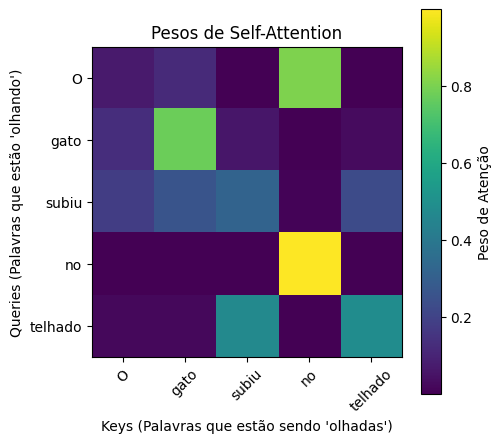

Matriz de Pesos de Atenção (Linha = Query, Coluna = Key):
[[0.073 0.117 0.002 0.808 0.001]
 [0.131 0.777 0.062 0.001 0.029]
 [0.183 0.262 0.319 0.01  0.227]
 [0.    0.    0.    1.    0.   ]
 [0.02  0.021 0.471 0.    0.488]]


In [7]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(5,5))
plt.imshow(attention_weights, cmap='viridis')
plt.xticks(ticks=np.arange(len(tokens)), labels=tokens, rotation=45)
plt.yticks(ticks=np.arange(len(tokens)), labels=tokens)
plt.xlabel("Keys (Palavras que estão sendo 'olhadas')")
plt.ylabel("Queries (Palavras que estão 'olhando')")
plt.title("Pesos de Self-Attention")
plt.colorbar(label='Peso de Atenção')
plt.show()

print("Matriz de Pesos de Atenção (Linha = Query, Coluna = Key):")
print(attention_weights.round(3))

# Matriz de Pesos de Atenção ($5 \times 5$)

Cada linha $i$ mostra como a palavra daquela linha distribuiu sua atenção entre todas as $5$ palavras da frase (a soma de cada linha é exatamente $1.0$ ou 100%).

Por exemplo, na linha referente ao token "subiu", as colunas mostram o peso numérico exato atribuído às palavras "O", "gato", "subiu", "no" e "telhado".

In [11]:
attention_weights.sum(axis=1)

array([1., 1., 1., 1., 1.])

## O Papel das Matrizes de Projeção $W_Q$ e $W_K$ treináveis

$\color{blue}{\text{
Vamos focar no em "Subiu" X "Gato" X "O"}}$

A palavra "subiu" entra no modelo como um vetor de embedding $X_{\text{subiu}}$. Para calcular a atenção, ele é multiplicado pela matriz treinável $W_Q$, gerando o vetor de Query $Q_{\text{subiu}}$:

$$Q_{\text{subiu}} = X_{\text{subiu}} \cdot W_Q$$

As palavras "gato" e "o" passam pela matriz $W_K$ para gerar seus respectivos vetores de Key:

$$K_{\text{gato}} = X_{\text{gato}} \cdot W_K$$ $$K_{\text{o}} = X_{\text{o}} \cdot W_K$$

O que as matrizes $W_Q$ e $W_K$ aprendem a fazer durante o treinamento?

- $W_Q$ transforma o verbo "subiu" em uma "busca" no espaço vetorial que aponta para características de entidades vivas / agentes capazes de realizar uma ação mecânica de ascensão (e para locais onde se pode subir).

- $W_K$ transforma o substantivo "gato" em uma "chave" que possui exatamente as características de um agente animado / sujeito de ações.

- $W_K$ transforma o artigo "o" em uma "chave" de função gramatical pura (determinador de gênero/número), sem conteúdo semântico de agente ou ação.




## "Exemplo" em 2D

Imagine um espaço simplificado de 2 dimensões:

- Eixo X: "Capacidade de ser o agente/sujeito da ação"
- Eixo Y: "Função de conectivo gramatical/artigo"

$\color{blue}{\text{
Uma representação "embedding" guarda algum tipo de "significado" (semântica/estrutura) em cada uma das posições.}}$

Durante o treinamento, o modelo ajusta as matrizes de forma que:

- $Q_{\text{subiu}} = [0.90, 0.05]$ (busca forte por agente, quase nula por artigo)
- $K_{\text{gato}} = [0.85, 0.10]$ (chave com alta capacidade de ser agente)
- $K_{\text{o}} = [0.02, 0.95]$ (chave predominantemente de função gramatical)

Calculando o produto escalar $Q \times K^T$:

- $\text{Score}(\text{subiu}, \text{gato}) = (0.90 \times 0.85) + (0.05 \times 0.10) = \mathbf{0.770} \quad \text{(Alto!)}$
- $\text{Score}(\text{subiu}, \text{o}) = (0.90 \times 0.02) + (0.05 \times 0.95) = \mathbf{0.0655} \quad \text{(Baixo!)}$

Após o treinamento as matrizes $W_Q$ e $W_K$ se estabiliza em um estado onde Queries e Keys de palavras semanticamente e sintaticamente relacionadas apontam para direções paralelas no espaço vetorial.

$\color{blue}{\text{
Vetores mais alinhados tem um valor maior (distância cosseno!).}}$

<br>
<small>
nota: Ainda há a redução de escala (com $\text{var}\left(\frac{Q K^T}{\sqrt{d_k}}\right) = 1$ a variância do produto escalar é reescalada de volta para $1$ evitando valores de magnitude elevada no treinamento e a saturação da `softmax`, $0$ ou $1$, que levaria a derivadas $0$ no treinamento) seguida da normalização da `softmax`.

## Matriz de Saída Final ($5 \times 3$)

É o resultado de multiplicar a tabela de pesos pela matriz de Valores $V$.

Cada linha é a nova representação vetorial da palavra, onde $\color{blue}{\text{a informação das outras palavras com alta pontuação de atenção foi "misturada" para compor seu novo significado contextual.}}$

In [14]:
for i, token in enumerate(tokens):
    weights_str = " ".join([f"{w:8.3f}" for w in attention_weights[i]])
    print(f"{token:10} {output[i]}")

O          [-2.50377197 -0.50496704  3.24360549]
gato       [0.94252657 0.33649442 0.18580801]
subiu      [ 0.71626024  0.2413474  -0.18927707]
no         [-3.28315813 -0.74708042  3.90558397]
telhado    [ 0.74648682 -0.00258405 -0.76414604]


## O Papel de $W_V$

O vetor original $X_{\text{gato}}$ é o vetor da palavra. A matriz $W_V$ atua como um filtro seletivo: ela projeta o vetor $X$ para transformar a representação bruta em um vetor $V$ focado na informação que é relevante para o contexto.


$\text{Novo_X}_{\text{subiu}} =(0.02 \times V_{\text{O}}) + (0.48 \times V_{\text{gato}}) + (0.05 \times V_{\text{subiu}}) + (0.03 \times V_{\text{no}}) +  (0.42 \times V_{\text{telhado}})  $

### Atenção Multi-Cabeça (Multi-Head Attention)

> Nos Transformers, a atenção ainda é dividida em várias "cabeças" operando em paralelo (ex: 8, 12, 16... cabeças). Cada cabeça possui a sua própria matriz $W_V^{(1)}, W_V^{(2)}, \dots, W_V^{(h)}$.


>> Cabeça 1 (Relações Sintáticas): A matriz $W_V^{(1)}$ projeta a palavra "gato" destacando seu papel de sujeito sintático.

>> Cabeça 2 (Relações Semânticas/Locais): A matriz $W_V^{(2)}$ projeta a palavra "telhado" destacando seu aspecto espacial de destino.

> etc.

> Sem a matriz $W_V$, todas as cabeças seriam forçadas a transmitir exatamente o mesmo conteúdo. A matriz $W_V$ permite ainda projetar o vetor para uma dimensão menor "$d_v = d_{\text{model}} / \text{número_de_cabeças}$", tornando a multiplicação de matrizes muito mais leve e eficiente na GPU.

## Resumo da Tríade $Q, K, V$

| Componente | O que faz? | Intuição no diálogo entre palavras |
|-|-|-|
| Query ($Q = X W_Q$) | Formula a busca | "Quem é o agente e o local da minha ação?" |
| Key ($K = X W_K$)| Define a etiqueta | "Eu sou um agente animado" / "Eu sou um local" |
| Value ($V = X W_V$) | Fornece a informação útil| "Se você precisa de mim, aqui está o meu conteúdo relevante" |

# **Encoder $\times$ Decoder**

```
===================================================================================
                       ARQUITETURA TRANSFORMER (ENCODER - DECODER)
===================================================================================

       [ ENCODER (Torre da Esquerda) ]               [ DECODER (Torre da Direita) ]
        Processa Entrada Completa                     Gera Saída Autorregressiva
      (Atenção Bidirecional Sem Máscara)             (Atenção Unidirecional com Máscara)
---------------------------------------------   ---------------------------------------------

         ┌─────────────────────────┐                     ┌─────────────────────────┐
         │     Saída do Encoder    │                     │ Probabilidades de Saída │
         │   (Matriz Contextual)   │                     │     (Linear + Softmax)  │
         └────────────┬────────────┘                     └────────────▲────────────┘
                      │                                               │
                      │                                  ┌────────────┴────────────┐
                      │                                  │      Add & Norm         │
                      │                                  └────────────▲────────────┘
                      │                                               │
                      │                                  ┌────────────┴────────────┐
                      │                                  │   Feed-Forward (FFN)    │
                      │                                  └────────────▲────────────┘
                      │                                               │
                      │                                  ┌────────────┴────────────┐
                      │                                  │      Add & Norm         │
                      │                                  └────────────▲────────────┘
                      │                                               │
                      │                                  ┌────────────┴────────────┐
                      │  Keys (K) & Values (V)           │ Cross-Attention (En-De) │
                      └─────────────────────────────────►│   Queries (Q) = Decoder │
                                                         │   Keys/Values = Encoder │
                                                         └────────────▲────────────┘
                      ┌─────────────────────────┐                     │
                      │      Add & Norm         │        ┌────────────┴────────────┐
                      └────────────▲────────────┘        │      Add & Norm         │
                                   │                     └────────────▲────────────┘
                      ┌────────────┴────────────┐                     │
                      │   Feed-Forward (FFN)    │        ┌────────────┴────────────┐
                      └────────────▲────────────┘        │ Masked Multi-Head Attn  │
                                   │                     │  (Mascara Causal -Inf)  │
                      ┌────────────┴────────────┐        └────────────▲────────────┘
                      │      Add & Norm         │                     │
                      └────────────▲────────────┘        ┌────────────┴────────────┐
                                   │                     │ Positional Encoding (+) │
                      ┌────────────┴────────────┐        │    Output Embedding     │
                      │ Multi-Head Self-Attn    │        └────────────▲────────────┘
                      │  (Atencao Bidirecional) │                     │
                      └────────────▲────────────┘        ┌────────────┴────────────┐
                                   │                     │ Tokens Gerados Até Agora│
                      ┌────────────┴────────────┐        │     "... e caiu"        │
                      │ Positional Encoding (+) │        └─────────────────────────┘
                      │     Input Embedding     │
                      └────────────▲────────────┘
                                   │
                      ┌────────────┴────────────┐
                      │  Entrada da Frase [X]   │
                      |O gato subiu  no telhado |
                      └─────────────────────────┘
===================================================================================
```

# **Arquiteturas Modernas de LLMs**

- **Encoder-Decoder (ex: T5, Whisper, Flan, BART)**: Mantém as duas torres conectadas pela Cross-Attention, ideal para *tarefas de tradução, sumarização e transcrição de áudio.*

- **Encoder-Only (ex: BERT)**: Usa apenas a torre Encoder (com atenção bidirecional sem máscara). *É excelente para extrair embeddings semânticos, buscas e classificação de texto*.

- **Decoder-Only (ex: GPT-4, Llama 3, Gemini, Phi-3)**: Usa apenas a torre Decoder (com máscara causal e remove a Cross-Attention). Como não há frase de entrada de outro idioma para traduzir, o prompt e a resposta são tratados como uma única sequência contínua gerada palavra por palavra. *Geração de texto: Chatbots, escrita criativa, criação de código e artigos.*



# **Um decoder mímino**

In [26]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Corpus de Treinamento (20 frases curtas)
corpus = [
    "O gato subiu no telhado",
    "O gato pulou no muro",
    "O cachorro subiu na mesa",
    "O cachorro correu na rua",
    "O gato bebeu o leite",
    "O gato dormiu no sofa",
    "O cachorro latiu no quintal",
    "O passaro voou no ceu",
    "O gato subiu na mesa",
    "O cachorro subiu no telhado",
    "O passaro pousou no telhado",
    "O gato correu no quintal",
    "O cachorro bebeu a agua",
    "O menino subiu no telhado",
    "O menino correu na rua",
    "O gato pulou na mesa",
    "O cachorro dormiu no sofa",
    "O passaro voou na rua",
    "O gato latiu no quintal",
    "O menino bebeu o leite"
]

# 2. Tokenização simples por palavras e construção do vocabulário
words = sorted(list(set(" ".join(corpus).split())))
vocab = {w: i for i, w in enumerate(words)}
inv_vocab = {i: w for i, w in enumerate(words)}
vocab_size = len(vocab)
tokenized_corpus = [[vocab[w] for w in s.split()] for s in corpus]

# 3. Arquitetura Minimal Decoder-Only Transformer
class MinimalDecoderOnly(nn.Module):
    def __init__(self, vocab_size, d_model=8, max_len=10):
        super().__init__()
        self.d_model = d_model

        # A) Embeddings (Token + Posição)
        self.tok_embed = nn.Embedding(vocab_size, d_model)
        self.pos_embed = nn.Embedding(max_len, d_model)

        # B) Atenção (1 Única Cabeça: Q, K, V)
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)

        # C) Feed-Forward Network (FFN)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, 16),
            nn.ReLU(),
            nn.Linear(16, d_model)
        )

        # D) LM Head (Projeção para o Vocabulário)
        self.lm_head = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        seq_len = x.size(1)
        positions = torch.arange(0, seq_len, device=x.device).unsqueeze(0)

        # 1. Soma Token + Posicional
        h = self.tok_embed(x) + self.pos_embed(positions)

        # 2. Projeções Q, K, V
        Q, K, V = self.W_q(h), self.W_k(h), self.W_v(h)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (self.d_model ** 0.5)

        # 3. MÁSCARA CAUSAL (Injeta -inf no futuro)
        mask = torch.triu(torch.ones(seq_len, seq_len, device=x.device), diagonal=1).bool()
        scores = scores.masked_fill(mask, float('-inf'))

        # 4. Softmax e Combinação dos Valores
        attn_weights = torch.softmax(scores, dim=-1)
        attn_out = torch.matmul(attn_weights, V)

        # 5. Conexões Residuais + FFN
        h = h + attn_out
        h = h + self.ffn(h)

        # 6. Logits do próximo token
        logits = self.lm_head(h)
        return logits, attn_weights

# 4. Treinamento
torch.manual_seed(42)
model = MinimalDecoderOnly(vocab_size=vocab_size, d_model=8, max_len=10)
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()

for epoch in range(1, 201):
    total_loss = 0
    for seq in tokenized_corpus:
        x_tensor = torch.tensor(seq[:-1]).unsqueeze(0) # Entrada: tokens [0 .. N-1]
        y_tensor = torch.tensor(seq[1:])               # Alvo:    tokens [1 .. N]

        optimizer.zero_grad()
        logits, _ = model(x_tensor)
        loss = criterion(logits.squeeze(0), y_tensor)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

# 5. Função de Geração Autorregressiva
def generate(prompt_text, max_new_tokens=3):
    model.eval()
    tokens = [vocab[w] for w in prompt_text.split() if w in vocab]
    with torch.no_grad():
        for _ in range(max_new_tokens):
            x_tensor = torch.tensor(tokens).unsqueeze(0)
            logits, _ = model(x_tensor)
            # Pega a previsão do próximo token na ÚLTIMA posição
            next_token_id = logits[0, -1, :].argmax().item()
            tokens.append(next_token_id)

    result = " ".join([inv_vocab[i] for i in tokens])
    print(f"Prompt: '{prompt_text:10}' -> Gerado: '{result}'")

print("--- RESULTADOS DA GERAÇÃO ---")
generate("O gato", 3)
generate("O cachorro", 3)
generate("O passaro", 3)
generate("O menino", 3)
generate("O gato", 2)
generate("O gato", 5)
generate("O", 5)

--- RESULTADOS DA GERAÇÃO ---
Prompt: 'O gato    ' -> Gerado: 'O gato subiu no telhado'
Prompt: 'O cachorro' -> Gerado: 'O cachorro subiu no telhado'
Prompt: 'O passaro ' -> Gerado: 'O passaro voou no ceu'
Prompt: 'O menino  ' -> Gerado: 'O menino correu na rua'
Prompt: 'O gato    ' -> Gerado: 'O gato subiu no'
Prompt: 'O gato    ' -> Gerado: 'O gato subiu no telhado no telhado'
Prompt: 'O         ' -> Gerado: 'O gato subiu no telhado no'
